In [2]:
# import libraries, these are alr downloaded from beforehand 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings 

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder 
warnings.filterwarnings('ignore')


In [3]:
df = pd.read_csv('C:\\Users\\panda\\OneDrive\\Documents\\NSDC\\predicting-life-insurance-lapse\\data\\CleanedLifeInsurance.csv')
df.head()

,ENTRY AGE,SEX,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,PAYMENT MODE,POLICY STATUS,BENEFIT,NON LAPSE GUARANTEED,SUBSTANDARD RISK,NUMBER OF ADVANCE PREMIUM,INITIAL BENEFIT,Full Benefit?,Policy Year (Decimal),Policy Year,Premium,Issue Date,is_lapse
0,36,F,1,1,A,Annually,Inforce,200000.0,NO NLG,0.0,0,0.0,N,8.000000,9,280.0,11-Aug,0
1,42,M,1,2,A,Annually,Inforce,100000.0,NO NLG,0.0,0,0.0,N,8.000000,9,200.0,11-Aug,0
2,40,M,2,3,A,Annually,Lapse,80000.0,NO NLG,0.0,0,0.0,N,8.000000,9,1289.0,11-Aug,1
3,39,M,1,2,A,Monthly,Lapse,100000.0,NO NLG,0.0,0,0.0,N,8.000000,9,216.0,11-Aug,1
4,44,M,1,2,A,Annually,Lapse,100000.0,NO NLG,0.0,0,0.0,N,7.916667,8,140.0,11-Sep,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 185560 entries, 0 to 185559
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ENTRY AGE                  185560 non-null  int64  
 1   SEX                        185560 non-null  str    
 2   POLICY TYPE 1              185560 non-null  int64  
 3   POLICY TYPE 2              185560 non-null  int64  
 4   POLICY TYPE 3              185560 non-null  str    
 5   PAYMENT MODE               185560 non-null  str    
 6   POLICY STATUS              185560 non-null  str    
 7   BENEFIT                    161896 non-null  float64
 8   NON LAPSE GUARANTEED       185560 non-null  str    
 9   SUBSTANDARD RISK           185560 non-null  float64
 10  NUMBER OF ADVANCE PREMIUM  185560 non-null  int64  
 11  INITIAL BENEFIT            185560 non-null  float64
 12  Full Benefit?              185560 non-null  str    
 13  Policy Year (Decimal)      185560 non-nu

In [5]:
# encoding categorical variables 
label_encoder = LabelEncoder()

for col in df.select_dtypes(include=['object']).columns:
    df[col] = label_encoder.fit_transform(df[col])

In [6]:
df.head()

,ENTRY AGE,SEX,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,PAYMENT MODE,POLICY STATUS,BENEFIT,NON LAPSE GUARANTEED,SUBSTANDARD RISK,NUMBER OF ADVANCE PREMIUM,INITIAL BENEFIT,Full Benefit?,Policy Year (Decimal),Policy Year,Premium,Issue Date,is_lapse
0,36,0,1,1,0,0,2,200000.0,3,0.0,0,0.0,0,8.000000,9,280.0,0,0
1,42,1,1,2,0,0,2,100000.0,3,0.0,0,0.0,0,8.000000,9,200.0,0,0
2,40,1,2,3,0,0,3,80000.0,3,0.0,0,0.0,0,8.000000,9,1289.0,0,1
3,39,1,1,2,0,1,3,100000.0,3,0.0,0,0.0,0,8.000000,9,216.0,0,1
4,44,1,1,2,0,0,3,100000.0,3,0.0,0,0.0,0,7.916667,8,140.0,4,1


In [7]:
# setup X and y for model training
# excluding issue date as a feature as it's prob not relevant and leads
# to complications when encoding the date 
X = df.drop(['is_lapse', 'Issue Date', 'POLICY STATUS'], axis = 1)
y = df['is_lapse']

In [8]:
# splitting dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
    )

In [9]:
clf = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    oob_score = True
    )
clf.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the followi

In [10]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1] # Probability of lapsing

# Check your actual performance 
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("\nDetailed Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.6682205216641518
ROC-AUC: 0.7287853313054193

Detailed Report:
               precision    recall  f1-score   support

           0       0.65      0.60      0.63     17120
           1       0.68      0.72      0.70     19992

    accuracy                           0.67     37112
   macro avg       0.67      0.66      0.66     37112
weighted avg       0.67      0.67      0.67     37112



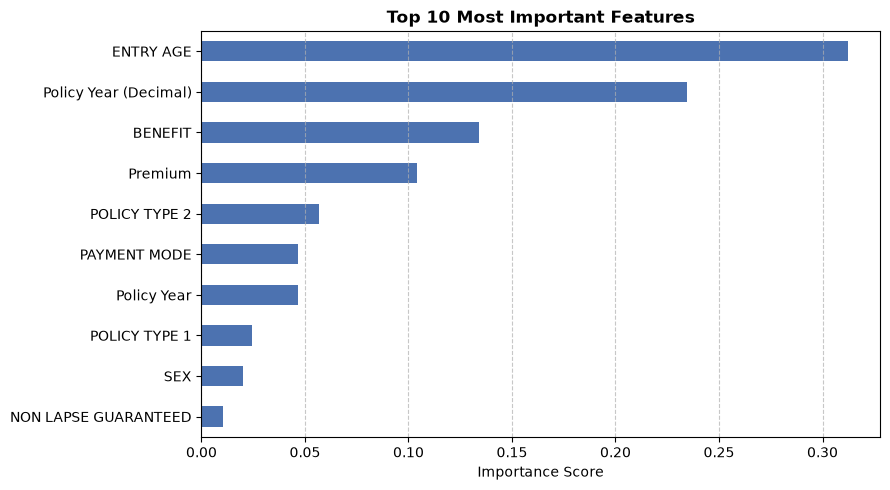

In [11]:

# Extract feature importances from trained random forest 
importances = clf.feature_importances_
features = X_train.columns
feat_imp = pd.Series(importances, index=features).nlargest(10)

# Plot
plt.figure(figsize=(9, 5))
feat_imp.plot(kind='barh', color='#4C72B0')
plt.title('Top 10 Most Important Features', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score', fontsize=10)
plt.gca().invert_yaxis()  # Most important at the top
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

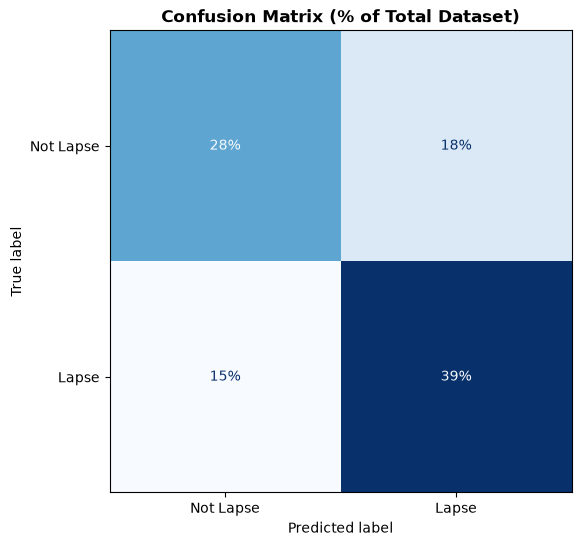

In [64]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    clf, X_test, y_test, 
    display_labels=['Not Lapse', 'Lapse'], 
    cmap='Blues', 
    ax=ax,
    colorbar=False,
    normalize='all',       # <--- Changes it so the ENTIRE grid sums to 100%
    values_format='.0%'    # Displays as percentages of the total dataset
)
plt.title('Confusion Matrix (% of Total Dataset)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()


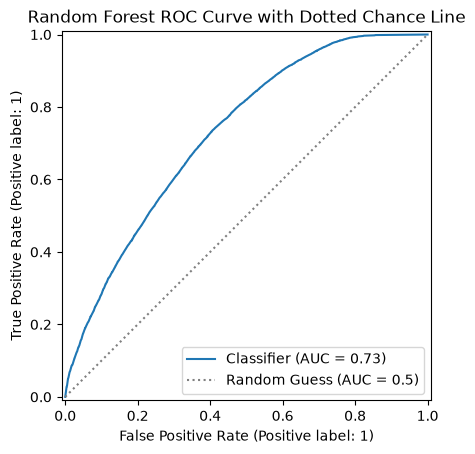

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# 1. Generate the ROC curve display
disp = RocCurveDisplay.from_predictions(y_test, y_prob)

# 2. Explicitly draw a DOTTED diagonal chance line (linestyle=':')
disp.ax_.plot([0, 1], [0, 1], linestyle=':', color='gray', label='Random Guess (AUC = 0.5)')

# 3. Refresh the legend to show your custom line
plt.legend()
plt.title("Random Forest ROC Curve with Dotted Chance Line")
plt.show()


In [15]:

# GridSearchCV tuning for Random Forest
from sklearn.model_selection import StratifiedKFold, GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "class_weight": [None, "balanced"],
}

REFIT_METRIC = "f1_macro"

grid = GridSearchCV(
    clf,
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring={"f1_macro": "f1_macro", "roc_auc": "roc_auc"},
    refit=REFIT_METRIC,
    n_jobs=2,
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(grid.best_params_)

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

# Evaluate tuned model...
# (Keep your evaluation and plotting code blocks unchanged)

{'class_weight': 'balanced', 'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}


In [66]:
# print best parameters 
print("\nBest Parameters Found:")
print(grid.best_params_)

# Check actual performance 
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))
print("\nDetailed Report:\n", classification_report(y_test, y_pred_tuned))

# compare with baseline model 
print("Baseline Model Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))


Best Parameters Found:
{'class_weight': 'balanced', 'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Accuracy: 0.6927947833584824
ROC-AUC: 0.7631341482270477

Detailed Report:
               precision    recall  f1-score   support

           0       0.71      0.56      0.63     17120
           1       0.68      0.80      0.74     19992

    accuracy                           0.69     37112
   macro avg       0.70      0.68      0.68     37112
weighted avg       0.70      0.69      0.69     37112

Baseline Model Performance:
Accuracy: 0.6682205216641518
ROC-AUC: 0.7287853313054193


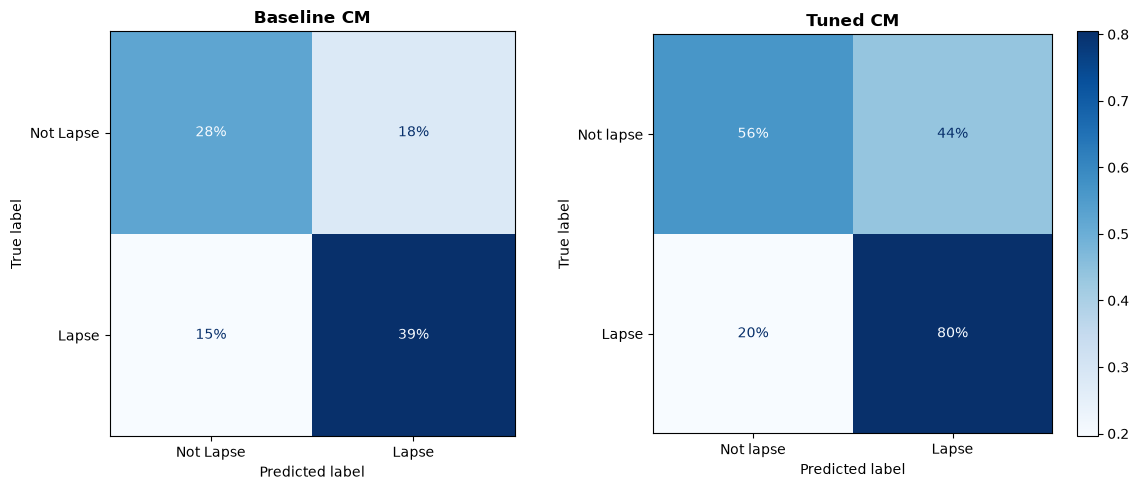

In [65]:

# Create a figure with 1 row and 2 columns for side-by-side display
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Baseline Confusion Matrix (% of Total Dataset)
ConfusionMatrixDisplay.from_estimator(
    clf, X_test, y_test, 
    display_labels=['Not Lapse', 'Lapse'], 
    cmap='Blues', 
    ax=axes[0],
    colorbar=False,
    normalize='all',       
    values_format='.0%'    
)
axes[0].set_title('Baseline CM', fontsize=12, fontweight='bold')
axes[0].grid(False)

# 2. Tuned Confusion Matrix (Row-wise / True Class Normalization)
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_tuned, 
    display_labels=["Not lapse", "Lapse"],
    cmap="Blues",
    normalize="true",  
    values_format=".0%", 
    ax=axes[1]
)
axes[1].set_title('Tuned CM', fontsize=12, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

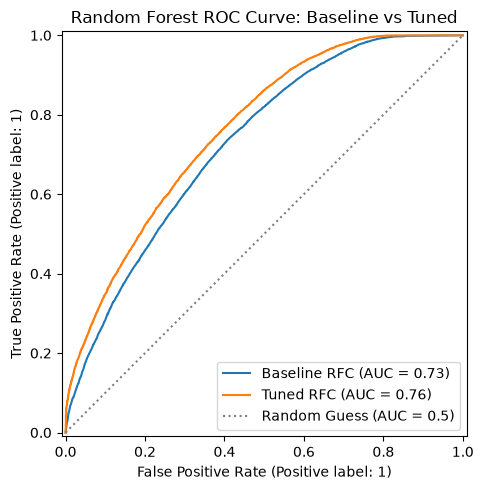

In [62]:

# 1. Create the figure with your desired width and height (e.g., width=10, height=5)
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_aspect("auto")
# 2. Plot Baseline ROC Curve on that axis
disp = RocCurveDisplay.from_predictions(y_test, y_prob, name="Baseline RFC", ax=ax)

# 3. Plot Tuned ROC Curve on the exact same axis
RocCurveDisplay.from_predictions(
    y_test, 
    y_prob_tuned, 
    name="Tuned RFC", 
    ax=ax
)

# 4. Draw the DOTTED diagonal chance line
ax.plot([0, 1], [0, 1], linestyle=':', color='gray', label='Random Guess (AUC = 0.5)')

# 5. Refresh the legend and title
ax.legend(loc="lower right")
ax.set_title("Random Forest ROC Curve: Baseline vs Tuned")

plt.tight_layout()
plt.show()